# Supplemental Figure 5, Panel B

Volcano plot of genes in nascent transcription at genes due to BAFinh. 

*Output: PanelB_BAFinh_volcano.pdf*

# Setup

In [1]:
library(tidyverse)
library(RColorBrewer)
library(ggrastr)
library(here)
here::i_am("figures/SuppFig5/PanelB/PanelB_volcano.ipynb")
sessionInfo()


── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.1.4     ✔ readr     2.1.5
✔ forcats   1.0.0     ✔ stringr   1.5.1
✔ ggplot2   3.5.2     ✔ tibble    3.2.1
✔ lubridate 1.9.4     ✔ tidyr     1.3.1
✔ purrr     1.0.2     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors
here() starts at /mnt/disk/home/agulka/manuscripts/BAF_stimulus_CellGenomics

here() starts at /mnt/disk/home/agulka/manuscripts/BAF_stimulus_CellGenomics



R version 4.2.2 Patched (2022-11-10 r83330)
Platform: x86_64-pc-linux-gnu (64-bit)
Running under: Ubuntu 23.04

Matrix products: default
BLAS:   /usr/lib/x86_64-linux-gnu/openblas-pthread/libblas.so.3
LAPACK: /usr/lib/x86_64-linux-gnu/openblas-pthread/libopenblasp-r0.3.21.so

locale:
 [1] LC_CTYPE=C.UTF-8       LC_NUMERIC=C           LC_TIME=C.UTF-8       
 [4] LC_COLLATE=C.UTF-8     LC_MONETARY=C.UTF-8    LC_MESSAGES=C.UTF-8   
 [7] LC_PAPER=C.UTF-8       LC_NAME=C              LC_ADDRESS=C          
[10] LC_TELEPHONE=C         LC_MEASUREMENT=C.UTF-8 LC_IDENTIFICATION=C   

attached base packages:
[1] stats     graphics  grDevices utils     datasets  methods   base     

other attached packages:
 [1] here_1.0.2         ggrastr_1.0.2      RColorBrewer_1.1-3 lubridate_1.9.4   
 [5] forcats_1.0.0      stringr_1.5.1      dplyr_1.1.4        purrr_1.0.2       
 [9] readr_2.1.5        tidyr_1.3.1        tibble_3.2.1       ggplot2_3.5.2     
[13] tidyverse_2.0.0   

loaded via a namespace (an

# load data

In [2]:
brm <- read.delim(
    here("inputs","DEGs","GM12878","BAFinh_stimulus","PROseq","PRO_DEGs_BAFinh_Veh.tsv"), 
    sep='\t')
str(brm)

'data.frame':	12437 obs. of  9 variables:
 $ ENSEMBL_ID    : chr  "ENSG00000188976" "ENSG00000187961" "ENSG00000188290" "ENSG00000187608" ...
 $ baseMean      : num  794.46 184.78 4.87 121.43 809.79 ...
 $ log2FoldChange: num  0.083 0.249 0.612 -0.526 0.163 ...
 $ lfcSE         : num  0.0858 0.1308 0.761 0.2429 0.0655 ...
 $ stat          : num  0.967 1.903 0.804 -2.164 2.49 ...
 $ pvalue        : num  0.3335 0.0571 0.4214 0.0304 0.0128 ...
 $ padj          : num  0.4485 0.1046 0.5375 0.0613 0.0287 ...
 $ gene          : chr  "NOC2L" "KLHL17" "HES4" "ISG15" ...
 $ change        : chr  "ns" "ns" "ns" "ns" ...


# Plotting function

In [19]:
volcano <- function(df){
    
    n <- df$change %>% table() # enumerate # of genes in each category (sig down, sig up, ns)
    
    plot <- ggplot(df, aes(x=log2FoldChange,y=-log10(padj))) +
    theme_bw() + theme(panel.grid=element_blank()) + 
    geom_vline(xintercept=c(-log2(1.5), log2(1.5)), linetype=2) +
    geom_hline(yintercept=-log10(.05), linetype=2) + 
    rasterize(geom_point(aes(color=change), size=.5), dpi=300)+
    xlim(-max(abs(df$log2FoldChange)), max(abs(df$log2FoldChange))) +
    scale_color_manual(values=c("down"= brewer.pal(3, "Paired")[2],
                                "ns" = "#aaaaaa", 
                                "up"=brewer.pal(6, "Paired")[6])) +
    ggtitle(paste("Down:", n[1], "Up:", n[3])) #annotate plot with #s of DEGs

    return(plot)
    }

Scale for x is already present.
Adding another scale for x, which will replace the existing scale.
Warning message:
“Removed 2 rows containing missing values or values outside the scale range
(`geom_point()`).”
Warning message:
“Removed 2 rows containing missing values or values outside the scale range
(`geom_point()`).”


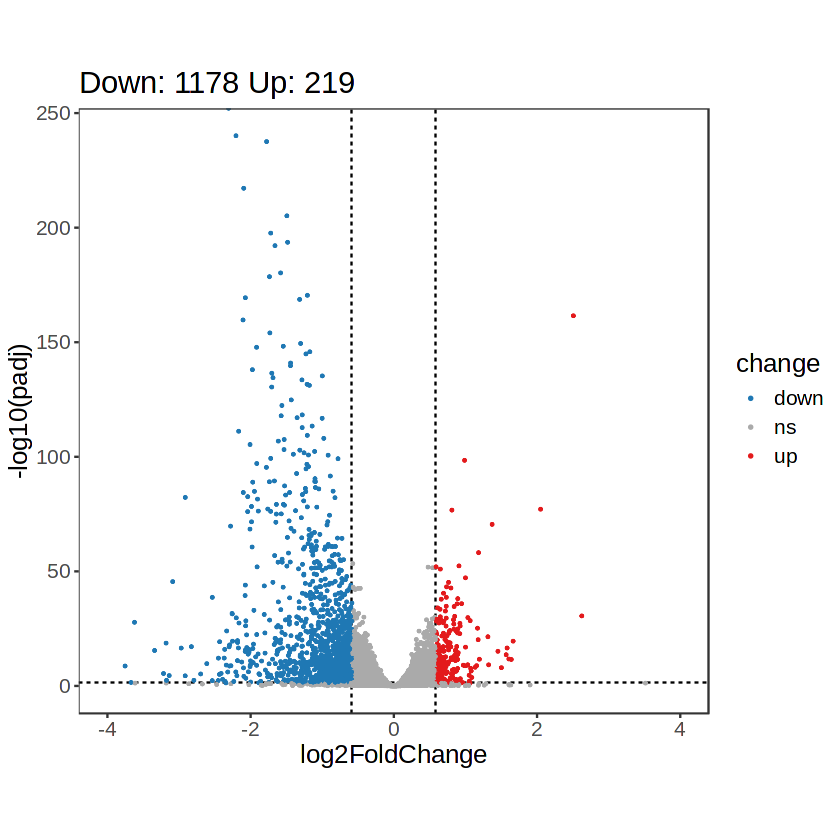

In [20]:
volcano(brm) + xlim(-4,4) + coord_fixed(ratio=8/250) + theme(text=element_text(size=15))
ggsave("PanelB_BAFinh_volcano.pdf", height=5, width=5)